In [1]:

# ============================================================
#  PREPARAÇÃO DOS DADOS - MCA PENSE 2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Arquivo de entrada
arquivo = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "08_PENSE2024_MCA_COORDENADAS.feather"
)

# Carregar dados
df_mca = pd.read_feather(arquivo)

print("=" * 65)
print("BASE DE COORDENADAS MCA - PENSE 2024")
print("=" * 65)

print(f"\nDimensões da base: {df_mca.shape}")
print(f"Quantidade de registros: {len(df_mca):,}")
print(f"Quantidade de colunas: {len(df_mca.columns)}")

# Identificar automaticamente colunas de coordenadas MCA
padrao_mca = re.compile(
    r"(dim|dimension|coord|axis|eixo|factor|component)",
    re.IGNORECASE
)

colunas_numericas = df_mca.select_dtypes(
    include=[np.number]
).columns.tolist()

colunas_mca = [
    c for c in colunas_numericas
    if padrao_mca.search(str(c))
]

# Caso os nomes não identifiquem as dimensões,
# utilizar todas as colunas numéricas, exceto identificadores.
if len(colunas_mca) < 2:

    colunas_mca = [
        c for c in colunas_numericas
        if not re.search(
            r"(^id$|^id_|_id$|codigo|código|identificador)",
            str(c),
            re.IGNORECASE
        )
    ]

print("\nColunas utilizadas na análise MCA:")
print(colunas_mca)

if len(colunas_mca) < 2:
    raise ValueError(
        "Não foram encontradas pelo menos duas colunas numéricas "
        "para realizar a clusterização."
    )

# Criar matriz de coordenadas
X = df_mca[colunas_mca].copy()

# Substituir valores infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remover registros com coordenadas ausentes
mascara_validos = X.notna().all(axis=1)

X = X.loc[mascara_validos].copy()

# Preservar índice dos registros originais
indices_validos = X.index

print("\nResultado da preparação:")
print(f"Registros válidos: {len(X):,}")
print(f"Registros removidos: {len(df_mca) - len(X):,}")
print(f"Dimensões MCA utilizadas: {X.shape[1]}")

# Converter para matriz NumPy
X_array = X.to_numpy(dtype=float)

# Identificar as duas primeiras dimensões para gráficos
dim1 = colunas_mca[0]
dim2 = colunas_mca[1]

print(f"\nGráficos utilizarão: {dim1} x {dim2}")


BASE DE COORDENADAS MCA - PENSE 2024

Dimensões da base: (118036, 21)
Quantidade de registros: 118,036
Quantidade de colunas: 21

Colunas utilizadas na análise MCA:
['indice_original', 'MCA_1', 'MCA_2', 'MCA_3', 'MCA_4', 'MCA_5', 'MCA_6', 'MCA_7', 'MCA_8', 'MCA_9', 'MCA_10', 'MCA_11', 'MCA_12', 'MCA_13', 'MCA_14', 'MCA_15', 'MCA_16', 'MCA_17', 'MCA_18', 'MCA_19', 'MCA_20']

Resultado da preparação:
Registros válidos: 118,036
Registros removidos: 0
Dimensões MCA utilizadas: 21

Gráficos utilizarão: indice_original x MCA_1


HAC - HIERARCHICAL AGGLOMERATIVE CLUSTERING

Registros utilizados: 5,000

Calculando dendrograma...


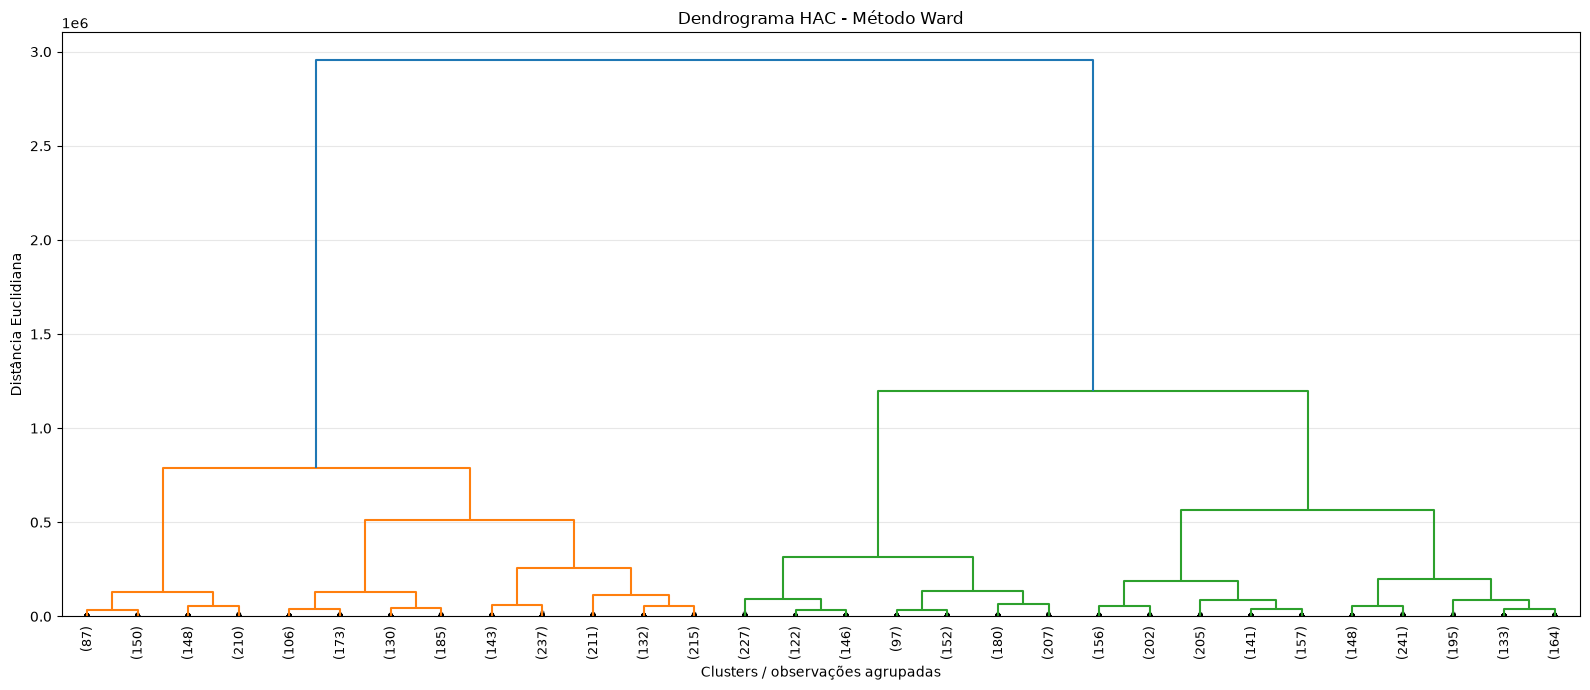


Avaliando diferentes números de clusters...

K=2 | Silhouette=0.6230
K=3 | Silhouette=0.5374
K=4 | Silhouette=0.5127
K=5 | Silhouette=0.5045
K=6 | Silhouette=0.5161
K=7 | Silhouette=0.5224
K=8 | Silhouette=0.5297
K=9 | Silhouette=0.5191
K=10 | Silhouette=0.5194

RESULTADOS HAC

Melhor número de clusters: 2
Silhouette Score: 0.6230

Distribuição dos clusters:
Cluster_HAC
0    2873
1    2127
Name: count, dtype: int64

Tabela comparativa:


,Clusters,Silhouette
0,2,0.6230
1,3,0.5374
2,4,0.5127
3,5,0.5045
4,6,0.5161
5,7,0.5224
6,8,0.5297
7,9,0.5191
8,10,0.5194


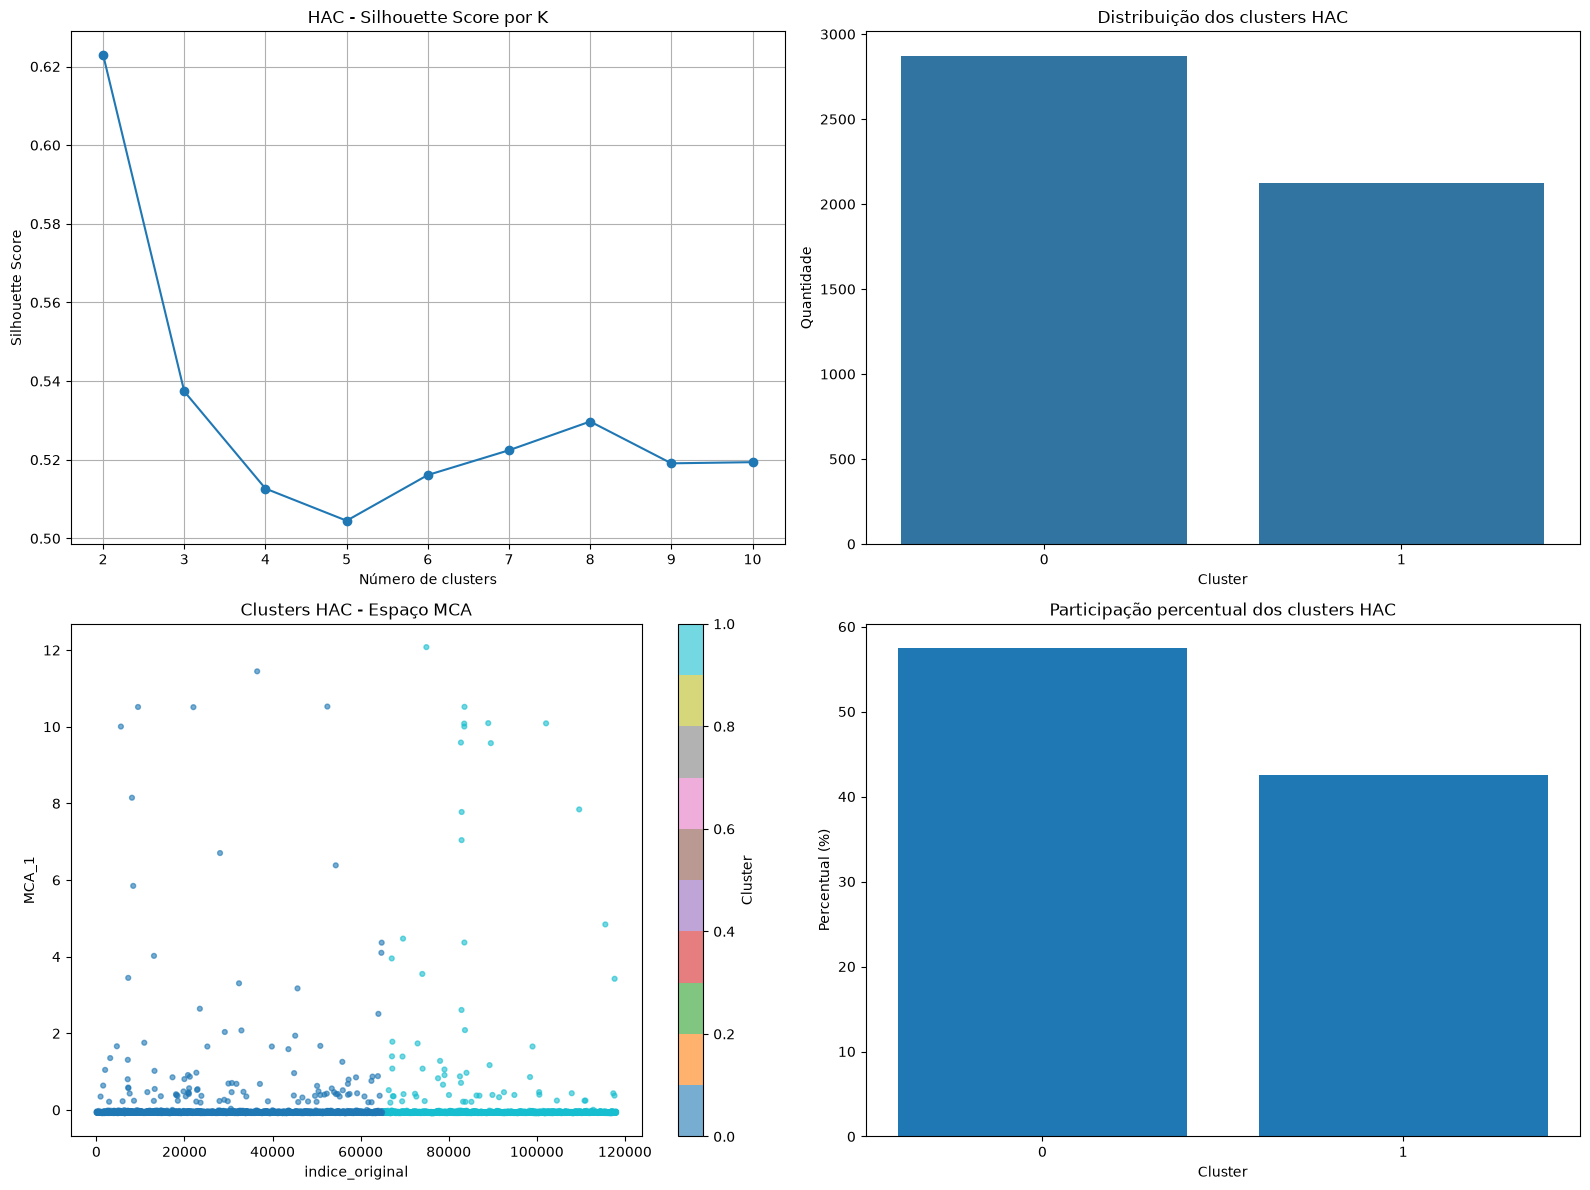


Médias das coordenadas MCA por cluster:


,indice_original,MCA_1,MCA_2,MCA_3,MCA_4,MCA_5,MCA_6,MCA_7,MCA_8,MCA_9,...,MCA_11,MCA_12,MCA_13,MCA_14,MCA_15,MCA_16,MCA_17,MCA_18,MCA_19,MCA_20
Cluster_HAC,,,,,,,,,,,,,,,,,,,,,
0,31856.4323,-0.0017,0.0185,-0.0052,-0.0136,0.0193,0.0032,0.0005,0.0203,0.0202,...,-0.0052,0.0139,0.0007,-0.0116,-0.0022,0.0039,-0.0078,-0.0122,-0.0066,-0.0005
1,91627.5905,0.0141,-0.0248,0.0193,0.0296,-0.0235,-0.0056,-0.0009,-0.0402,-0.0237,...,-0.0022,-0.0263,-0.0015,0.0156,0.0058,0.0003,0.0020,0.0140,0.0064,-0.0090


In [2]:

# ============================================================
#  HAC - HIERARCHICAL AGGLOMERATIVE CLUSTERING
#  PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Parâmetros
MAX_AMOSTRA_HAC = 5000
K_MIN_HAC = 2
K_MAX_HAC = 10

# Selecionar amostra
if len(X) > MAX_AMOSTRA_HAC:

    rng = np.random.RandomState(42)

    indices_hac = rng.choice(
        len(X),
        MAX_AMOSTRA_HAC,
        replace=False
    )

else:
    indices_hac = np.arange(len(X))

X_hac = X_array[indices_hac]

print("=" * 65)
print("HAC - HIERARCHICAL AGGLOMERATIVE CLUSTERING")
print("=" * 65)

print(f"\nRegistros utilizados: {len(X_hac):,}")

# ============================================================
# DENDROGRAMA
# ============================================================

print("\nCalculando dendrograma...")

# Ward minimiza o aumento da variância intra-cluster
matriz_linkage = linkage(
    X_hac,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(16, 7))

dendrogram(
    matriz_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title("Dendrograma HAC - Método Ward")
plt.xlabel("Clusters / observações agrupadas")
plt.ylabel("Distância Euclidiana")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# TESTAR DIFERENTES NÚMEROS DE CLUSTERS
# ============================================================

resultados_hac = []
modelos_hac = {}

print("\nAvaliando diferentes números de clusters...\n")

for k in range(K_MIN_HAC, K_MAX_HAC + 1):

    modelo = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )

    labels = modelo.fit_predict(X_hac)

    score = silhouette_score(
        X_hac,
        labels
    )

    modelos_hac[k] = modelo

    resultados_hac.append({
        "Clusters": k,
        "Silhouette": score
    })

    print(f"K={k} | Silhouette={score:.4f}")

df_hac = pd.DataFrame(resultados_hac)

# Melhor K pelo Silhouette
melhor_k_hac = int(
    df_hac.loc[
        df_hac["Silhouette"].idxmax(),
        "Clusters"
    ]
)

# Modelo final
modelo_hac = modelos_hac[melhor_k_hac]

clusters_hac = modelo_hac.labels_

# ============================================================
# RESULTADOS
# ============================================================

df_resultado_hac = df_mca.iloc[
    indices_validos[indices_hac]
].copy()

df_resultado_hac["Cluster_HAC"] = clusters_hac

print("\n" + "=" * 65)
print("RESULTADOS HAC")
print("=" * 65)

print(f"\nMelhor número de clusters: {melhor_k_hac}")

print(
    f"Silhouette Score: "
    f"{df_hac['Silhouette'].max():.4f}"
)

print("\nDistribuição dos clusters:")

print(
    df_resultado_hac["Cluster_HAC"]
    .value_counts()
    .sort_index()
)

print("\nTabela comparativa:")

display(df_hac.round(4))

# ============================================================
# GRÁFICOS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 - Silhouette por K
axes[0, 0].plot(
    df_hac["Clusters"],
    df_hac["Silhouette"],
    marker="o"
)

axes[0, 0].set_title("HAC - Silhouette Score por K")
axes[0, 0].set_xlabel("Número de clusters")
axes[0, 0].set_ylabel("Silhouette Score")
axes[0, 0].grid(True)

# 2 - Distribuição
sns.countplot(
    x="Cluster_HAC",
    data=df_resultado_hac,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Distribuição dos clusters HAC")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].set_ylabel("Quantidade")

# 3 - Coordenadas MCA
scatter = axes[1, 0].scatter(
    X_hac[:, 0],
    X_hac[:, 1],
    c=clusters_hac,
    cmap="tab10",
    s=12,
    alpha=0.6
)

axes[1, 0].set_title("Clusters HAC - Espaço MCA")
axes[1, 0].set_xlabel(dim1)
axes[1, 0].set_ylabel(dim2)

plt.colorbar(scatter, ax=axes[1, 0], label="Cluster")

# 4 - Tamanho percentual dos clusters
percentuais = (
    df_resultado_hac["Cluster_HAC"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

axes[1, 1].bar(
    percentuais.index.astype(str),
    percentuais.values
)

axes[1, 1].set_title("Participação percentual dos clusters HAC")
axes[1, 1].set_xlabel("Cluster")
axes[1, 1].set_ylabel("Percentual (%)")

plt.tight_layout()
plt.show()

# ============================================================
# CENTROS MÉDIOS DOS CLUSTERS
# ============================================================

print("\nMédias das coordenadas MCA por cluster:")

display(
    df_resultado_hac.groupby("Cluster_HAC")[colunas_mca]
    .mean()
    .round(4)
)



AVALIAÇÃO AMPLIADA HAC - PENSE 2024

MÉTRICAS GERAIS


,Metrica,Resultado
0,Silhouette Score,6.230000e-01
1,Calinski-Harabasz,1.448735e+04
2,Davies-Bouldin,4.943000e-01
3,SSE Total,1.506342e+12
4,Distancia media entre centroides,5.977116e+04
5,Cluster Balance (entropia),9.839000e-01
6,Razao maior/menor cluster,1.350700e+00
7,Cophenetic Correlation,7.521000e-01



SILHOUETTE POR CLUSTER


,Media,Mediana,Desvio_Padrao,Minimo,Maximo,Observacoes
Cluster,,,,,,
0,0.5851,0.6928,0.2323,-0.2008,0.7483,2873
1,0.6742,0.7339,0.1426,0.2052,0.7852,2127



DISPERSÃO INTERNA POR CLUSTER


,Cluster,Quantidade,SSE,SSE_Medio
0,0,2873,9.975555e+11,3.472174e+08
1,1,2127,5.087867e+11,2.392039e+08



EQUILÍBRIO DOS CLUSTERS


,Cluster,Quantidade,Percentual
0,0,2873,57.46
1,1,2127,42.54



DISTÂNCIA ENTRE CENTROIDES


,Cluster 0,Cluster 1
Cluster 0,0.0000,59771.1582
Cluster 1,59771.1582,0.0000


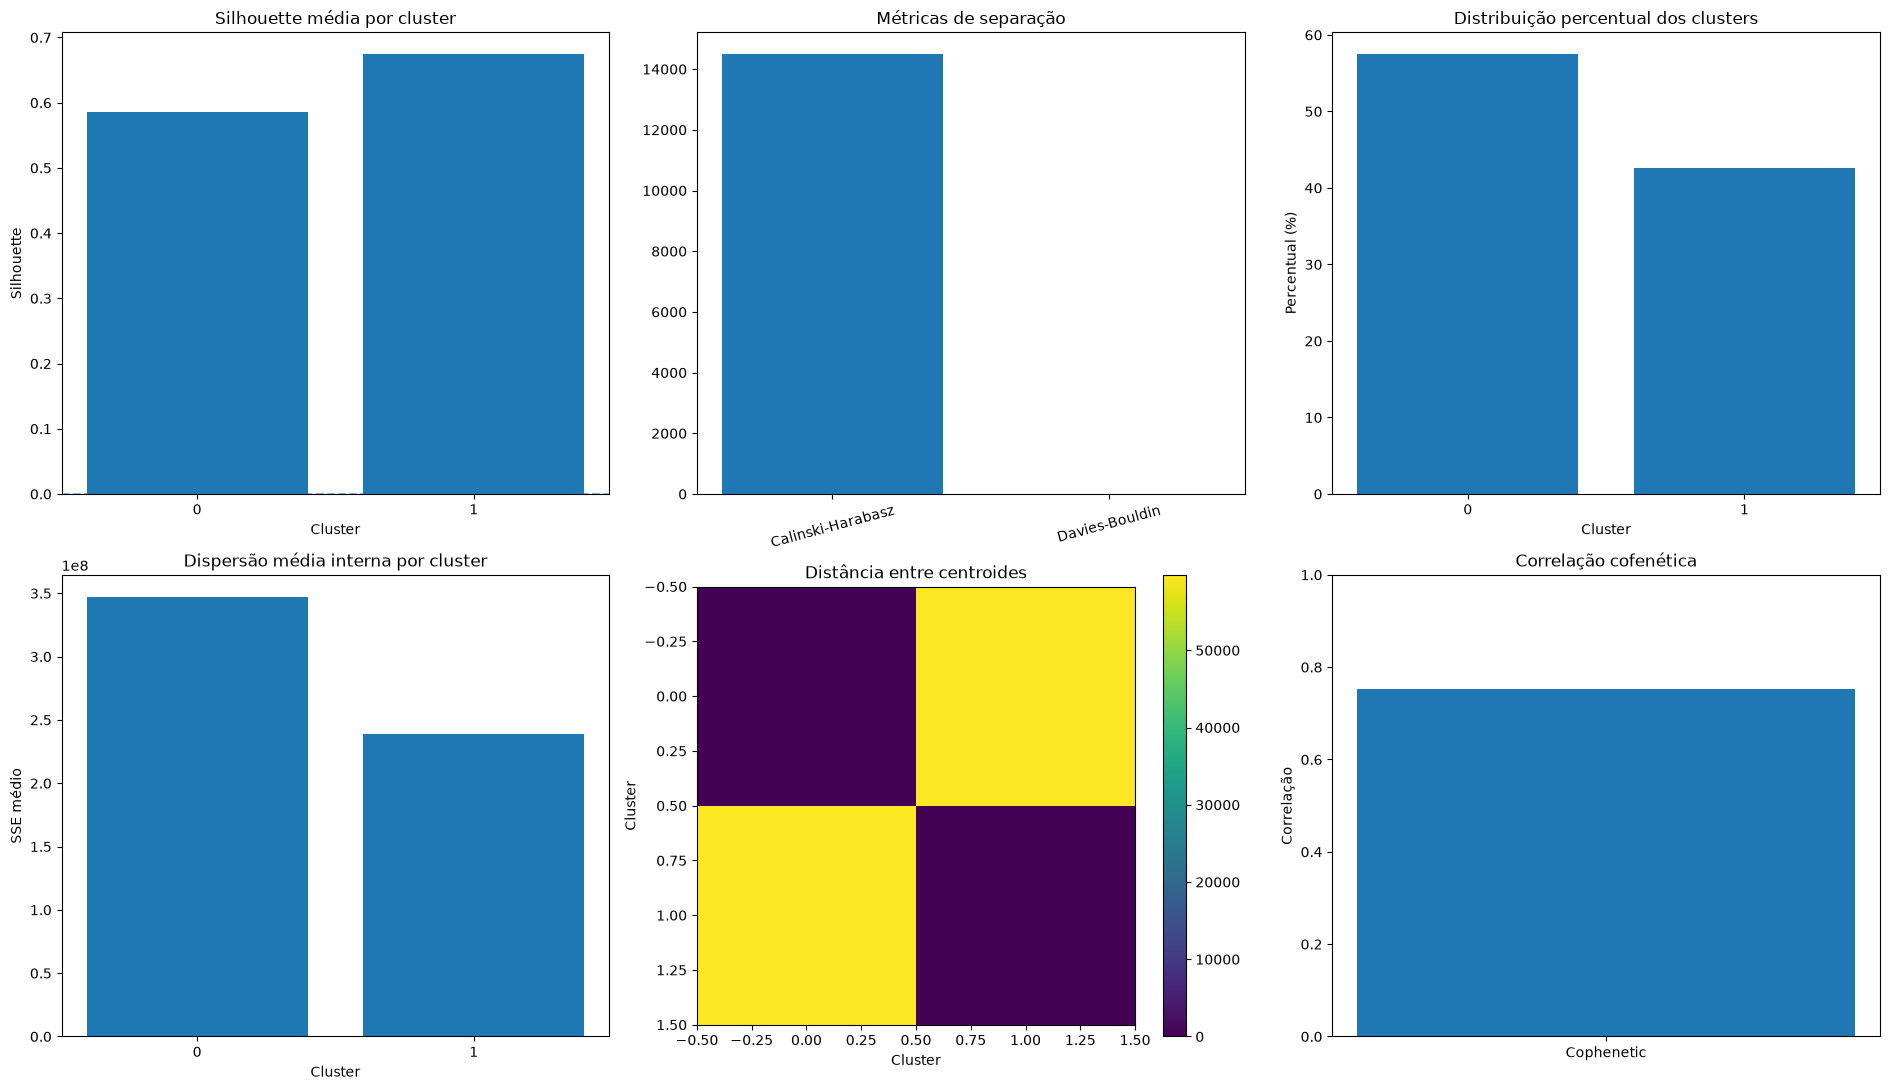


Avaliação ampliada HAC concluída.


In [3]:

# ============================================================
# 9. MÉTRICAS ADICIONAIS DE AVALIAÇÃO DO HAC
# PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
    adjusted_rand_score,
    pairwise_distances
)

from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist

# ------------------------------------------------------------
# 9.1. PREPARAÇÃO DOS DADOS
# ------------------------------------------------------------

# Utilizar exatamente a amostra e os clusters do HAC original

X_avaliacao_hac = X_hac
labels_hac = clusters_hac

K_FINAL_HAC = melhor_k_hac

# ------------------------------------------------------------
# 9.2. CALINSKI-HARABASZ INDEX
# ------------------------------------------------------------

ch_score_hac = calinski_harabasz_score(
    X_avaliacao_hac,
    labels_hac
)

# ------------------------------------------------------------
# 9.3. DAVIES-BOULDIN INDEX
# ------------------------------------------------------------

db_score_hac = davies_bouldin_score(
    X_avaliacao_hac,
    labels_hac
)

# ------------------------------------------------------------
# 9.4. SILHOUETTE POR CLUSTER
# ------------------------------------------------------------

silhouette_individual_hac = silhouette_samples(
    X_avaliacao_hac,
    labels_hac
)

df_silhouette_hac = pd.DataFrame({
    "Cluster": labels_hac,
    "Silhouette": silhouette_individual_hac
})

silhouette_clusters_hac = (
    df_silhouette_hac
    .groupby("Cluster")["Silhouette"]
    .agg(["mean", "median", "std", "min", "max", "count"])
    .round(4)
)

silhouette_clusters_hac.columns = [
    "Media",
    "Mediana",
    "Desvio_Padrao",
    "Minimo",
    "Maximo",
    "Observacoes"
]

# ------------------------------------------------------------
# 9.5. DISPERSÃO INTERNA - SSE
# ------------------------------------------------------------

dispersao_hac = []

centroides_hac = []

for k in range(K_FINAL_HAC):

    mascara = labels_hac == k

    dados_cluster = X_avaliacao_hac[mascara]

    centroide = dados_cluster.mean(axis=0)

    centroides_hac.append(centroide)

    distancias_quadradas = np.sum(
        (dados_cluster - centroide) ** 2,
        axis=1
    )

    dispersao_hac.append({
        "Cluster": k,
        "Quantidade": len(dados_cluster),
        "SSE": distancias_quadradas.sum(),
        "SSE_Medio": distancias_quadradas.mean()
    })

df_dispersao_hac = pd.DataFrame(dispersao_hac)

centroides_hac = np.array(centroides_hac)

SSE_TOTAL_HAC = df_dispersao_hac["SSE"].sum()

# ------------------------------------------------------------
# 9.6. EQUILÍBRIO DOS CLUSTERS
# ------------------------------------------------------------

tamanhos_hac = np.bincount(
    labels_hac,
    minlength=K_FINAL_HAC
)

percentuais_hac = (
    tamanhos_hac / len(labels_hac)
) * 100

df_balance_hac = pd.DataFrame({
    "Cluster": range(K_FINAL_HAC),
    "Quantidade": tamanhos_hac,
    "Percentual": percentuais_hac
})

# Razão entre maior e menor cluster
razao_balance_hac = (
    tamanhos_hac.max() / tamanhos_hac.min()
    if tamanhos_hac.min() > 0 else np.inf
)

# Entropia normalizada do tamanho dos clusters
proporcoes_hac = tamanhos_hac / tamanhos_hac.sum()

entropia_hac = -np.sum(
    proporcoes_hac[proporcoes_hac > 0] *
    np.log(proporcoes_hac[proporcoes_hac > 0])
)

entropia_balance_hac = (
    entropia_hac / np.log(K_FINAL_HAC)
    if K_FINAL_HAC > 1 else np.nan
)

# ------------------------------------------------------------
# 9.7. DISTÂNCIA ENTRE CENTROIDES
# ------------------------------------------------------------

distancias_centroides_hac = pairwise_distances(
    centroides_hac,
    metric="euclidean"
)

df_distancias_hac = pd.DataFrame(
    distancias_centroides_hac,
    index=[f"Cluster {k}" for k in range(K_FINAL_HAC)],
    columns=[f"Cluster {k}" for k in range(K_FINAL_HAC)]
)

# Média das distâncias entre centroides distintos
mascara_superior = np.triu(
    np.ones(distancias_centroides_hac.shape, dtype=bool),
    k=1
)

distancia_media_centroides_hac = (
    distancias_centroides_hac[mascara_superior].mean()
)

# ------------------------------------------------------------
# 9.8. CORRELAÇÃO COFENÉTICA
# ------------------------------------------------------------

# Mede quanto o dendrograma preserva as distâncias originais.
# O cálculo pode consumir memória em amostras grandes.

CALCULAR_COPHENETIC = True

if CALCULAR_COPHENETIC:

    distancia_original = pdist(
        X_avaliacao_hac,
        metric="euclidean"
    )

    correlacao_cophenetic, distancias_cophenetic = cophenet(
        matriz_linkage,
        distancia_original
    )

    del distancia_original
    del distancias_cophenetic

else:

    correlacao_cophenetic = np.nan

# ------------------------------------------------------------
# 9.9. RESULTADOS CONSOLIDADOS
# ------------------------------------------------------------

silhouette_medio_hac = silhouette_score(
    X_avaliacao_hac,
    labels_hac
)

resultados_metricas_hac = pd.DataFrame({

    "Metrica": [
        "Silhouette Score",
        "Calinski-Harabasz",
        "Davies-Bouldin",
        "SSE Total",
        "Distancia media entre centroides",
        "Cluster Balance (entropia)",
        "Razao maior/menor cluster",
        "Cophenetic Correlation"
    ],

    "Resultado": [
        silhouette_medio_hac,
        ch_score_hac,
        db_score_hac,
        SSE_TOTAL_HAC,
        distancia_media_centroides_hac,
        entropia_balance_hac,
        razao_balance_hac,
        correlacao_cophenetic
    ]
})

print("\n" + "=" * 75)
print("AVALIAÇÃO AMPLIADA HAC - PENSE 2024")
print("=" * 75)

print("\nMÉTRICAS GERAIS")

display(resultados_metricas_hac.round(4))

print("\nSILHOUETTE POR CLUSTER")

display(silhouette_clusters_hac)

print("\nDISPERSÃO INTERNA POR CLUSTER")

display(df_dispersao_hac.round(4))

print("\nEQUILÍBRIO DOS CLUSTERS")

display(df_balance_hac.round(2))

print("\nDISTÂNCIA ENTRE CENTROIDES")

display(df_distancias_hac.round(4))

# ------------------------------------------------------------
# 9.10. GRÁFICOS DAS MÉTRICAS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Gráfico 1 - Silhouette por cluster

axes[0, 0].bar(
    silhouette_clusters_hac.index.astype(str),
    silhouette_clusters_hac["Media"]
)

axes[0, 0].axhline(
    0,
    linestyle="--",
    alpha=0.5
)

axes[0, 0].set_title("Silhouette média por cluster")
axes[0, 0].set_xlabel("Cluster")
axes[0, 0].set_ylabel("Silhouette")

# Gráfico 2 - Calinski-Harabasz e Davies-Bouldin

axes[0, 1].bar(
    ["Calinski-Harabasz", "Davies-Bouldin"],
    [ch_score_hac, db_score_hac]
)

axes[0, 1].set_title("Métricas de separação")
axes[0, 1].tick_params(axis="x", rotation=15)

# Gráfico 3 - Distribuição dos clusters

axes[0, 2].bar(
    df_balance_hac["Cluster"].astype(str),
    df_balance_hac["Percentual"]
)

axes[0, 2].set_title("Distribuição percentual dos clusters")
axes[0, 2].set_xlabel("Cluster")
axes[0, 2].set_ylabel("Percentual (%)")

# Gráfico 4 - Dispersão interna

axes[1, 0].bar(
    df_dispersao_hac["Cluster"].astype(str),
    df_dispersao_hac["SSE_Medio"]
)

axes[1, 0].set_title("Dispersão média interna por cluster")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("SSE médio")

# Gráfico 5 - Distância entre centroides

im = axes[1, 1].imshow(
    distancias_centroides_hac,
    cmap="viridis"
)

axes[1, 1].set_title("Distância entre centroides")
axes[1, 1].set_xlabel("Cluster")
axes[1, 1].set_ylabel("Cluster")

plt.colorbar(im, ax=axes[1, 1])

# Gráfico 6 - Correlação cofenética

if not np.isnan(correlacao_cophenetic):

    axes[1, 2].bar(
        ["Cophenetic"],
        [correlacao_cophenetic]
    )

    axes[1, 2].set_ylim(0, 1)

    axes[1, 2].set_title("Correlação cofenética")
    axes[1, 2].set_ylabel("Correlação")

else:

    axes[1, 2].text(
        0.5, 0.5,
        "Não calculada",
        ha="center",
        va="center"
    )

    axes[1, 2].set_title("Correlação cofenética")
    axes[1, 2].set_axis_off()

plt.tight_layout()
plt.show()

print("\nAvaliação ampliada HAC concluída.")


Repetição 1: 3000 observações
Repetição 2: 3000 observações
Repetição 3: 3000 observações

ESTABILIDADE DOS CLUSTERS HAC


,Modelo A,Modelo B,Observacoes_comuns,ARI
0,1,2,1804,0.2773
1,1,3,1787,0.5831
2,2,3,1810,0.0659



ARI médio: 0.3088
Desvio padrão: 0.2600


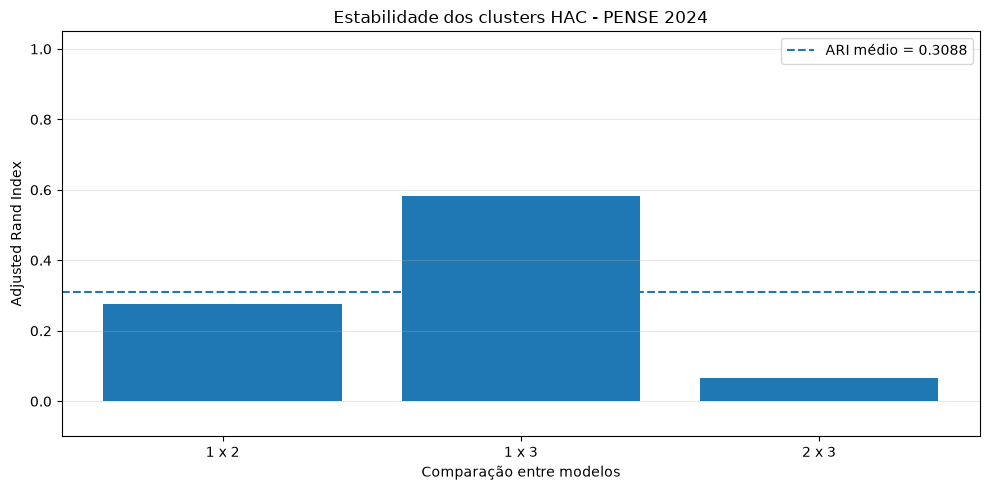


Análise de estabilidade HAC concluída.


In [4]:

# ============================================================
# 10. ESTABILIDADE DOS CLUSTERS HAC
# ADJUSTED RAND INDEX (ARI)
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# ------------------------------------------------------------
# PARÂMETROS
# ------------------------------------------------------------

N_REPETICOES_HAC = 3
PERCENTUAL_AMOSTRA_HAC = 0.60

rng = np.random.default_rng(42)

resultados_modelos_hac = {}

# ------------------------------------------------------------
# 10.1. EXECUTAR HAC EM DIFERENTES SUBAMOSTRAS
# ------------------------------------------------------------

for repeticao in range(N_REPETICOES_HAC):

    n_amostra = int(
        len(X_hac) * PERCENTUAL_AMOSTRA_HAC
    )

    indices_repeticao = rng.choice(
        len(X_hac),
        size=n_amostra,
        replace=False
    )

    X_repeticao = X_hac[indices_repeticao]

    modelo_repeticao = AgglomerativeClustering(
        n_clusters=melhor_k_hac,
        linkage="ward",
        metric="euclidean"
    )

    labels_repeticao = modelo_repeticao.fit_predict(
        X_repeticao
    )

    # Guardar índice original dentro de X_hac e cluster
    resultados_modelos_hac[repeticao] = dict(
        zip(indices_repeticao, labels_repeticao)
    )

    print(
        f"Repetição {repeticao + 1}: "
        f"{len(indices_repeticao)} observações"
    )

# ------------------------------------------------------------
# 10.2. COMPARAR OS MODELOS
# ------------------------------------------------------------

comparacoes_ari_hac = []

for modelo_a, modelo_b in combinations(
    range(N_REPETICOES_HAC), 2
):

    dados_a = resultados_modelos_hac[modelo_a]
    dados_b = resultados_modelos_hac[modelo_b]

    # Observações presentes nas duas amostras
    indices_comuns = sorted(
        set(dados_a.keys()) & set(dados_b.keys())
    )

    labels_a = [
        dados_a[i] for i in indices_comuns
    ]

    labels_b = [
        dados_b[i] for i in indices_comuns
    ]

    ari = adjusted_rand_score(
        labels_a,
        labels_b
    )

    comparacoes_ari_hac.append({
        "Modelo A": modelo_a + 1,
        "Modelo B": modelo_b + 1,
        "Observacoes_comuns": len(indices_comuns),
        "ARI": ari
    })

df_estabilidade_hac = pd.DataFrame(
    comparacoes_ari_hac
)

# ------------------------------------------------------------
# 10.3. RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ESTABILIDADE DOS CLUSTERS HAC")
print("=" * 70)

display(df_estabilidade_hac.round(4))

ari_medio_hac = df_estabilidade_hac["ARI"].mean()

ari_desvio_hac = df_estabilidade_hac["ARI"].std()

print(f"\nARI médio: {ari_medio_hac:.4f}")
print(f"Desvio padrão: {ari_desvio_hac:.4f}")

# ------------------------------------------------------------
# 10.4. GRÁFICO
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

nomes_comparacao = [
    f"{int(row['Modelo A'])} x {int(row['Modelo B'])}"
    for _, row in df_estabilidade_hac.iterrows()
]

plt.bar(
    nomes_comparacao,
    df_estabilidade_hac["ARI"]
)

plt.axhline(
    ari_medio_hac,
    linestyle="--",
    label=f"ARI médio = {ari_medio_hac:.4f}"
)

plt.ylim(-0.1, 1.05)

plt.title("Estabilidade dos clusters HAC - PENSE 2024")
plt.xlabel("Comparação entre modelos")
plt.ylabel("Adjusted Rand Index")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nAnálise de estabilidade HAC concluída.")
